In [1]:
# 데이터 로드
from sklearn.datasets import fetch_openml
mnist=fetch_openml('mnist_784', version=1)

In [2]:
# train, test split
X_train = mnist['data'][:60000]
y_train = mnist['target'][:60000]
X_test = mnist['data'][60000:]
y_test = mnist['target'][60000:]

* 랜덤포레스트에 적용

In [4]:
# 랜덤포레스트에 적용 (n_estimators=10, random_state=42)
#from sklearn import set_config
#set_config(display="text")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_clf = RandomForestClassifier(n_estimators=10, random_state=42)
rf_clf.fit(X_train, y_train)


RandomForestClassifier(n_estimators=10, random_state=42)

In [6]:
# 정확도 결과
pred = rf_clf.predict(X_test)
print(accuracy_score(y_test, pred))

0.9492


# 1. PCA

* PCA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [7]:
# PCA 라이브러리 불러오기
from sklearn.decomposition import PCA

In [23]:
# PCA 적용 95% : n_components=0.95 -> 전체 분산의 95%를 설명할 만큼의 주성분을 자동으로 생성
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(pca.n_components_)
print(X_train_pca.shape)
print(X_test_pca.shape)

154
(60000, 154)
(10000, 154)


In [9]:
# PCA 이후 랜덤포레스트 훈련
rf_pca = RandomForestClassifier(n_estimators=10, random_state=42)
rf_pca.fit(X_train_pca, y_train)

RandomForestClassifier(n_estimators=10, random_state=42)

In [10]:
# 정확도 결과 (X_test도 PCA 적용해야합니다.)
pred_pca = rf_pca.predict(X_test_pca)
print(f"PCA(95%) 적용 후 정확도: {accuracy_score(y_test, pred_pca):.4f}")

PCA(95%) 적용 후 정확도: 0.8925


**관련 문제**

* PCA모델을 와인 데이터셋에 적용하여 차원을 축소하고 그 결과를 그래프로 나타내보세요.

(1) 필요한 모듈 불러오기

In [11]:
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

(2)  load_wine을 사용해 데이터셋을 생성한다.

In [12]:
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

(3) X에 표준 스케일링(Standard scaling)을 적용하여 X_scaled을 생성한다.

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_wine)

(4) PCA 모델을 X에 적용하여 2개의 차원으로 추출한다. 단, random_state=1234로 설정한다.

In [15]:
#PCA 모델을 X_scaled에 적용하여 2개의 차원으로 추출한다.

pca_wine = PCA(n_components=2, random_state=1234)
wine_pca = pca_wine.fit_transform(X_scaled)

wine_df = pd.DataFrame(wine_pca, columns=["PC1", "PC2"])
wine_df["target"] = y_wine

wine_df.head(3)

,PC1,PC2,target
0,3.316751,1.443463,0
1,2.209465,-0.333393,0
2,2.516740,1.031151,0


(5) 추출한 피처를 그래프로 나타내라.

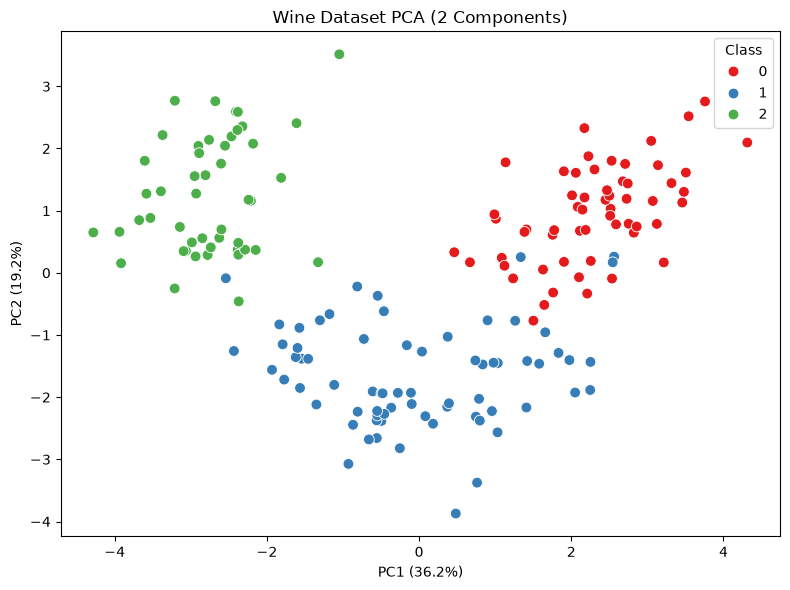

In [16]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=wine_df, x="PC1", y="PC2", hue="target", palette="Set1", s=60)
plt.title("Wine Dataset PCA (2 Components)")
plt.xlabel(f"PC1 ({pca_wine.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca_wine.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [25]:
print(pca_wine.explained_variance_ratio_)

[0.36198848 0.1920749 ]


# 2. LDA

- LDA로 변환한 데이터 세트에 랜덤 포레스트 적용

In [17]:
# LDA 라이브러리 불러오기
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [18]:
# LDA 적용 : n_components=5
lda = LinearDiscriminantAnalysis(n_components=5)
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

In [19]:
# LDA 이후 랜덤포레스트 훈련
rf_lda = RandomForestClassifier(n_estimators=10, random_state=42)
rf_lda.fit(X_train_lda, y_train)

RandomForestClassifier(n_estimators=10, random_state=42)

In [20]:
# 정확도 결과 (X_test도 LDA 적용해야합니다.)
pred_lda = rf_lda.predict(X_test_lda)
print(f"LDA 적용 후 정확도: {accuracy_score(y_test, pred_lda):.4f}")

LDA 적용 후 정확도: 0.8301
